# 1 Environment setup

In [6]:
!pip install qiskit
!pip install qiskit-machine-learning

In [2]:
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import clear_output

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC

from qiskit.circuit.library import zz_feature_map
from qiskit.circuit.library import real_amplitudes
from qiskit.circuit.library import efficient_su2

from qiskit.primitives import StatevectorSampler

from qiskit_machine_learning.algorithms.classifiers import VQC
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

SEED = 123
np.random.seed(SEED)
algorithm_globals.random_seed = SEED

# 2 Part I — Exploring the dataset

In [52]:
iris_data = load_iris()

data = iris_data

sample_number, feature_number = data.data.shape
number_classes = len(np.unique(data.target))


feature_names = data.feature_names
target_names = data.target_names
class_name = target_names[data.target]

print(data)
print(feature_names)


import collections
class_counts = collections.Counter(data.target)
class_balance_status = "balanced" if len(set(class_counts.values())) == 1 else "unbalanced"
print(class_balance_status)

print(target_names)

{'data': array([[5.1, 3.5, 1.4, 0.2],
       [4.9, 3. , 1.4, 0.2],
       [4.7, 3.2, 1.3, 0.2],
       [4.6, 3.1, 1.5, 0.2],
       [5. , 3.6, 1.4, 0.2],
       [5.4, 3.9, 1.7, 0.4],
       [4.6, 3.4, 1.4, 0.3],
       [5. , 3.4, 1.5, 0.2],
       [4.4, 2.9, 1.4, 0.2],
       [4.9, 3.1, 1.5, 0.1],
       [5.4, 3.7, 1.5, 0.2],
       [4.8, 3.4, 1.6, 0.2],
       [4.8, 3. , 1.4, 0.1],
       [4.3, 3. , 1.1, 0.1],
       [5.8, 4. , 1.2, 0.2],
       [5.7, 4.4, 1.5, 0.4],
       [5.4, 3.9, 1.3, 0.4],
       [5.1, 3.5, 1.4, 0.3],
       [5.7, 3.8, 1.7, 0.3],
       [5.1, 3.8, 1.5, 0.3],
       [5.4, 3.4, 1.7, 0.2],
       [5.1, 3.7, 1.5, 0.4],
       [4.6, 3.6, 1. , 0.2],
       [5.1, 3.3, 1.7, 0.5],
       [4.8, 3.4, 1.9, 0.2],
       [5. , 3. , 1.6, 0.2],
       [5. , 3.4, 1.6, 0.4],
       [5.2, 3.5, 1.5, 0.2],
       [5.2, 3.4, 1.4, 0.2],
       [4.7, 3.2, 1.6, 0.2],
       [4.8, 3.1, 1.6, 0.2],
       [5.4, 3.4, 1.5, 0.4],
       [5.2, 4.1, 1.5, 0.1],
       [5.5, 4.2, 1.4, 0.2],
     

# Questions

1/ Each sample represents an individual iris flower, characterized by four distinct features.

2/ The four measured features are: sepal length (cm), sepal width (cm), petal length (cm), and petal width (cm).

3/ Yes, the dataset is balanced. It contains 150 samples in total, with 50 samples for each of the three classes (Setosa, Versicolor, and Virginica).

4/ It is a multiclass classification problem, as there are 3 distinct classes (Setosa, Versicolor, Virginica) to predict.

# 2.2 Visualizing the data

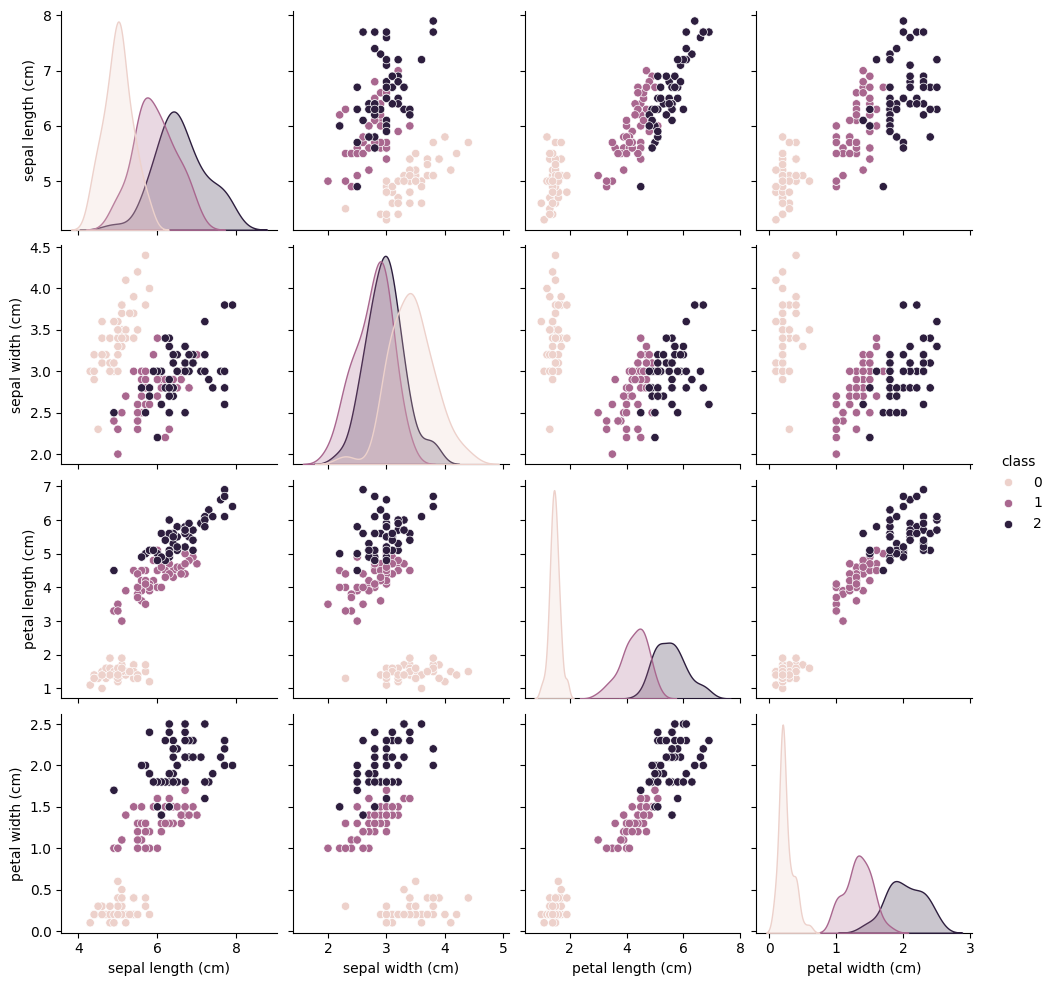

In [54]:
df = pd.DataFrame(iris_data.data, columns=iris_data.feature_names)
df["class"] = pd.Series(iris_data.target)

sns.pairplot(df, hue="class")

# Plot analysis


Features that appear most useful for classification:
petal length (cm) and petal width (cm) appear to be the most useful features for distinguishing between the different Iris species.

Classes that appear easiest to separate:
The setosa class (class 0) is the easiest to separate from the other two classes. It forms a distinct cluster in almost all plots, especially when considering petal length and petal width.

Classes that show the greatest overlap:
The versicolor (class 1) and virginica (class 2) classes show the greatest overlap, particularly where their petal lengths and petal widths are similar.

#Part II — Preparing the Data

In [55]:
features = MinMaxScaler().fit_transform(iris_data.data)


print(features)
for i, feature_name in enumerate(iris_data.feature_names):
    min_val = features[:, i].min()
    max_val = features[:, i].max()
    print(f"Feature '{feature_name}': Min = {min_val}, Max = {max_val}")



[[0.22222222 0.625      0.06779661 0.04166667]
 [0.16666667 0.41666667 0.06779661 0.04166667]
 [0.11111111 0.5        0.05084746 0.04166667]
 [0.08333333 0.45833333 0.08474576 0.04166667]
 [0.19444444 0.66666667 0.06779661 0.04166667]
 [0.30555556 0.79166667 0.11864407 0.125     ]
 [0.08333333 0.58333333 0.06779661 0.08333333]
 [0.19444444 0.58333333 0.08474576 0.04166667]
 [0.02777778 0.375      0.06779661 0.04166667]
 [0.16666667 0.45833333 0.08474576 0.        ]
 [0.30555556 0.70833333 0.08474576 0.04166667]
 [0.13888889 0.58333333 0.10169492 0.04166667]
 [0.13888889 0.41666667 0.06779661 0.        ]
 [0.         0.41666667 0.01694915 0.        ]
 [0.41666667 0.83333333 0.03389831 0.04166667]
 [0.38888889 1.         0.08474576 0.125     ]
 [0.30555556 0.79166667 0.05084746 0.125     ]
 [0.22222222 0.625      0.06779661 0.08333333]
 [0.38888889 0.75       0.11864407 0.08333333]
 [0.22222222 0.75       0.08474576 0.08333333]
 [0.30555556 0.58333333 0.11864407 0.04166667]
 [0.22222222 

# Questions

1/ It is useful for scaling. Example: Huge values and small values would be scale between 0 and 1 and be more explicit for our model. Features with larger numerical ranges can dominate the learning process.

2/

3/ It could lead to an invalid angle ranges or to a loss of interpretability.
It becomes much harder to design, debug, and interpret the behavior of the quantum feature map if the input features are not on a consistent and predictable scale.

# 3.2 Training and test sets

In [60]:
train_feature, test_feature, train_labels, test_labels = train_test_split(features, iris_data.target, train_size=0.8, test_size=0.2, random_state=SEED)

print(train_feature)
print("#######")
print(test_feature)
print("#######")
print(train_labels)
print("#######")
print(test_labels)

[[0.86111111 0.33333333 0.86440678 0.75      ]
 [0.47222222 0.08333333 0.6779661  0.58333333]
 [0.11111111 0.5        0.10169492 0.04166667]
 [0.22222222 0.625      0.06779661 0.04166667]
 [0.47222222 0.08333333 0.50847458 0.375     ]
 [0.19444444 0.125      0.38983051 0.375     ]
 [1.         0.75       0.91525424 0.79166667]
 [0.30555556 0.79166667 0.11864407 0.125     ]
 [0.30555556 0.79166667 0.05084746 0.125     ]
 [0.41666667 0.29166667 0.49152542 0.45833333]
 [0.19444444 0.         0.42372881 0.375     ]
 [0.19444444 0.5        0.03389831 0.04166667]
 [0.69444444 0.5        0.83050847 0.91666667]
 [0.66666667 0.41666667 0.71186441 0.91666667]
 [0.41666667 0.29166667 0.69491525 0.75      ]
 [0.41666667 0.33333333 0.69491525 0.95833333]
 [0.55555556 0.58333333 0.77966102 0.95833333]
 [0.33333333 0.125      0.50847458 0.5       ]
 [0.22222222 0.75       0.08474576 0.08333333]
 [0.02777778 0.41666667 0.05084746 0.04166667]
 [0.61111111 0.5        0.69491525 0.79166667]
 [0.22222222 

#Questions

1/ The test set should not be used for training because our NN could be overfitted and if we want to determine a data that is not in our training set, the answer have high probabilities to be false.

2/ It may lead to overfitting. The model performs exceptionally well on the data it has seen during training. t struggles to generalize to new data.

# 4 Part III — Classical baseline

In [108]:
svc_quantum = SVC(random_state=SEED)

svc_quantum.fit(train_feature, train_labels)
score_test = svc_quantum.score(test_feature, test_labels)
score_training = svc_quantum.score(train_feature, train_labels)

print(score_training)
print(score_test)

0.9916666666666667
0.9666666666666667


#Questions

1/ The fidelity of the SVC is at 97% regarding the test set.

2/ No, there is no evidence of overfitting.

# 5 Part IV — Designing the quantum model

In [63]:
zz_feature = zz_feature_map(4, 1)

zz_feature.draw()

┌───┐┌───────────┐                                               »
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■────■──»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐  │  »
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──┼──»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                          └───┘»
3: ┤ H ├┤ P(2*x[3]) ├───────────────────────────────────────────────»
   └───┘└───────────┘                                               »
«                                                                             »
«0: ──────────────────────────────────■────■──────────────────────────────────»
«                                     │    │                                  »
«1: ──────────────────────────────────┼────┼─────────────────■────────────────»
«   ┌──────────────────────────────┐┌─┴─┐  │               ┌─┴─┐              »
«2: ┤ P((-π + x[0])*(-π + x[2])*2) ├┤ X ├──┼───────────────┤ X ├──────────────»
«   └──────────────────────────────┘└───┘┌─┴─┐┌────────────┴───┴─────────────┐»
«3: ─────────────────────────────────────┤ X ├┤ P((-π + x[0])*(-π + x[3])*2) ├»
«                                        └───┘└──────────────────────────────┘»
«                                                  »
«0: ──────────────────────────────────■────────────»
«                                     │            »
«1: ──────────────────────────────────┼────■────■──»
«   ┌──────────────────────────────┐  │  ┌─┴─┐  │  »
«2: ┤ P((-π + x[1])*(-π + x[2])*2) ├──┼──┤ X ├──┼──»
«   └──────────────────────────────┘┌─┴─┐└───┘┌─┴─┐»
«3: ────────────────────────────────┤ X ├─────┤ X ├»
«                                   └───┘     └───┘»
«                                                                             »
«0: ──────────────────────────────────────────────────────────────────────────»
«                                                                             »
«1: ──────────────────────────────────■───────────────────────────────────────»
«                                     │                                       »
«2: ──────────────────────────────────┼────■──────────────────────────────────»
«   ┌──────────────────────────────┐┌─┴─┐┌─┴─┐┌──────────────────────────────┐»
«3: ┤ P((-π + x[1])*(-π + x[3])*2) ├┤ X ├┤ X ├┤ P((-π + x[2])*(-π + x[3])*2) ├»
«   └──────────────────────────────┘└───┘└───┘└──────────────────────────────┘»
«        
«0: ─────
«        
«1: ─────
«        
«2: ──■──
«   ┌─┴─┐
«3: ┤ X ├
«   └───┘

# Questions

1/ Four qubits are used because the Iris dataset has four features.

2/ The purpose of the ZZ interactions is to encode the input data into the quantum state. While single-qubit rotations encode individual feature values, two-qubit entangling gates like RZZ allow the circuit to capture relationships and interactions between pairs of features.

In [74]:
ansatz = real_amplitudes(4, reps=3)
ansatz.draw()

┌──────────┐                             ┌──────────┐             »
q_0: ┤ Ry(θ[0]) ├──────────────────────■──────┤ Ry(θ[4]) ├─────────────»
     ├──────────┤                    ┌─┴─┐    ├──────────┤             »
q_1: ┤ Ry(θ[1]) ├──────────■─────────┤ X ├────┤ Ry(θ[5]) ├──────■──────»
     ├──────────┤        ┌─┴─┐    ┌──┴───┴───┐└──────────┘    ┌─┴─┐    »
q_2: ┤ Ry(θ[2]) ├──■─────┤ X ├────┤ Ry(θ[6]) ├─────■──────────┤ X ├────»
     ├──────────┤┌─┴─┐┌──┴───┴───┐└──────────┘   ┌─┴─┐    ┌───┴───┴───┐»
q_3: ┤ Ry(θ[3]) ├┤ X ├┤ Ry(θ[7]) ├───────────────┤ X ├────┤ Ry(θ[11]) ├»
     └──────────┘└───┘└──────────┘               └───┘    └───────────┘»
«                  ┌──────────┐                          ┌───────────┐
«q_0: ──────■──────┤ Ry(θ[8]) ├───────────────────■──────┤ Ry(θ[12]) ├
«         ┌─┴─┐    ├──────────┤                 ┌─┴─┐    ├───────────┤
«q_1: ────┤ X ├────┤ Ry(θ[9]) ├──────■──────────┤ X ├────┤ Ry(θ[13]) ├
«     ┌───┴───┴───┐└──────────┘    ┌─┴─┐    ┌───┴───┴───┐└───────────┘
«q_2: ┤ Ry(θ[10]) ├─────■──────────┤ X ├────┤ Ry(θ[14]) ├─────────────
«     └───────────┘   ┌─┴─┐    ┌───┴───┴───┐└───────────┘             
«q_3: ────────────────┤ X ├────┤ Ry(θ[15]) ├──────────────────────────
«                     └───┘    └───────────┘

## Questions

1/ For a real_amplitudes circuit with n qubits and reps repetitions, the number of trainable parameters is typically n * (reps + 1).

2/ The number of single-qubit rotation layers in a real_amplitudes circuit is equal to reps + 1. With 3 reps, there are 3 + 1 = 4 layers of single-qubit Ry rotations.

3/ Increasing the number of repetitions generally increases the depth of the circuit. A deeper circuit with more repetitions can model more complex relationships and entanglement patterns in the data.

4/

In [75]:
cobyla_optimizer = COBYLA(maxiter=100)
print(cobyla_optimizer.settings)

{'maxiter': 100, 'disp': False, 'rhobeg': 1.0, 'max_evals_grouped': 1, 'options': {}, 'tol': None}


## Questions

1/ The COBYLA optimizer, when used with a VQC, is trying to minimize a loss function. This cost function quantifies the discrepancy between the VQC's predictions and the true labels of the training data. The optimizer iteratively adjusts the VQC's trainable parameters to find a set of parameters that results in the lowest possible cost.

# 6 Part V — Training the VQC

In [89]:
objective_func_vals = []
plt.rcParams["figure.figsize"] = (12, 6)

def callback_graph(weights, obj_func_eval):
  clear_output(wait=True)
  objective_func_vals.append(obj_func_eval)
  plt.title("Objective function value against iteration")
  plt.xlabel("Iteration")
  plt.ylabel("Objective function value")
  plt.plot(range(len(objective_func_vals)), objective_func_vals)
  plt.show()

In [91]:
vqc = VQC(feature_map=zz_feature, ansatz=ansatz, optimizer=cobyla_optimizer, sampler=StatevectorSampler(), callback=callback_graph)

print(vqc.feature_map, vqc.ansatz, vqc.optimizer)

   ┌───┐┌───────────┐                                               »
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■────■──»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐  │  »
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──┼──»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                          └───┘»
3: ┤ H ├┤ P(2*x[3]) ├───────────────────────────────────────────────»
   └───┘└───────────┘                                               »
«                                                                             »
«0: ──────────────────────────────────■────■──────────────────────────────────»
«                                     │    │                                  »
«1: ──────────────────────────────────┼────┼─────────────────■────────────────»
«   ┌──────────────────────────────┐┌─┴─┐  │      

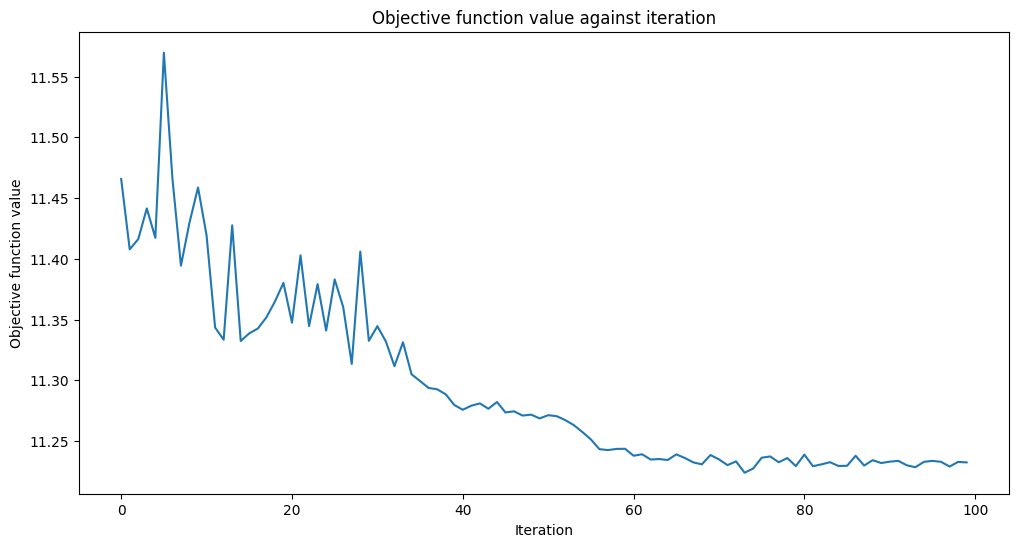

Training time: 122.55 seconds
Final objective function value: 11.2239
Number of optimization cycles: 100


In [92]:
start_time = time.time()
vqc.fit(train_feature, train_labels)
end_time = time.time()

training_time = end_time - start_time
final_objective_value = vqc._fit_result.fun
num_optimization_cycles = vqc._fit_result.nfev

print(f"Training time: {training_time:.2f} seconds")
print(f"Final objective function value: {final_objective_value:.4f}")
print(f"Number of optimization cycles: {num_optimization_cycles}")

#Questions

1/ Yes the objective function decrease.

2/ No the decrease is not monotonic. Some times the value can increase at certain iteration.

3/ At approximately 58-59 iterations, the value is stable

In [107]:
score_training = vqc.score(train_feature, train_labels)
score_test = vqc.score(test_feature, test_labels)

print(score_training)
print(score_test)

0.6166666666666667
0.5666666666666667


#Questions

1/ No, the vqc does not generalize well, the score for the test is ~56

2/ The SVC (0.99) seems to be more performant than VQC (0.62) on the training set.

3/ Same for the test set. 0.97 for SVC and 0.57 for VQC.

4/ Yes it seems that SVC is way more performative thant VQC.

#Part VI — Investigating the ansatz

In [94]:
ansatz_2 = efficient_su2(4, reps=3)

ansatz_2.draw()

┌──────────┐┌──────────┐                                ┌──────────┐»
q_0: ┤ Ry(θ[0]) ├┤ Rz(θ[4]) ├────────────────────────■───────┤ Ry(θ[8]) ├»
     ├──────────┤├──────────┤                      ┌─┴─┐     ├──────────┤»
q_1: ┤ Ry(θ[1]) ├┤ Rz(θ[5]) ├───────────■──────────┤ X ├─────┤ Ry(θ[9]) ├»
     ├──────────┤├──────────┤         ┌─┴─┐    ┌───┴───┴───┐┌┴──────────┤»
q_2: ┤ Ry(θ[2]) ├┤ Rz(θ[6]) ├──■──────┤ X ├────┤ Ry(θ[10]) ├┤ Rz(θ[14]) ├»
     ├──────────┤├──────────┤┌─┴─┐┌───┴───┴───┐├───────────┤└───────────┘»
q_3: ┤ Ry(θ[3]) ├┤ Rz(θ[7]) ├┤ X ├┤ Ry(θ[11]) ├┤ Rz(θ[15]) ├─────────────»
     └──────────┘└──────────┘└───┘└───────────┘└───────────┘             »
«     ┌───────────┐                          ┌───────────┐┌───────────┐»
«q_0: ┤ Rz(θ[12]) ├───────────────────■──────┤ Ry(θ[16]) ├┤ Rz(θ[20]) ├»
«     ├───────────┤                 ┌─┴─┐    ├───────────┤├───────────┤»
«q_1: ┤ Rz(θ[13]) ├──────■──────────┤ X ├────┤ Ry(θ[17]) ├┤ Rz(θ[21]) ├»
«     └───────────┘    ┌─┴─┐    ┌───┴───┴───┐├───────────┤└───────────┘»
«q_2: ──────■──────────┤ X ├────┤ Ry(θ[18]) ├┤ Rz(θ[22]) ├──────■──────»
«         ┌─┴─┐    ┌───┴───┴───┐├───────────┤└───────────┘    ┌─┴─┐    »
«q_3: ────┤ X ├────┤ Ry(θ[19]) ├┤ Rz(θ[23]) ├─────────────────┤ X ├────»
«         └───┘    └───────────┘└───────────┘                 └───┘    »
«                               ┌───────────┐┌───────────┐
«q_0: ───────────────────■──────┤ Ry(θ[24]) ├┤ Rz(θ[28]) ├
«                      ┌─┴─┐    ├───────────┤├───────────┤
«q_1: ──────■──────────┤ X ├────┤ Ry(θ[25]) ├┤ Rz(θ[29]) ├
«         ┌─┴─┐    ┌───┴───┴───┐├───────────┤└───────────┘
«q_2: ────┤ X ├────┤ Ry(θ[26]) ├┤ Rz(θ[30]) ├─────────────
«     ┌───┴───┴───┐├───────────┤└───────────┘             
«q_3: ┤ Ry(θ[27]) ├┤ Rz(θ[31]) ├──────────────────────────
«     └───────────┘└───────────┘

In [97]:
print(f"Number of trainable parameters for real_amplitudes: {ansatz.num_parameters}")
print(f"Number of trainable parameters for efficient_su2: {ansatz_2.num_parameters}")
print(f"Circuit depth for real_amplitudes: {ansatz.depth()}")

print(f"Circuit depth for efficient_su2: {ansatz_2.depth()}")

Number of trainable parameters for real_amplitudes: 16
Number of trainable parameters for efficient_su2: 32
Circuit depth for real_amplitudes: 11
Circuit depth for efficient_su2: 15


###structure of the rotations layers

*   real_amplitudes: Primarily uses single-qubit Ry gates in its rotation layers. These gates rotate the qubit state around the Y-axis of the Bloch's sphere.
*   efficient_su2: Uses both single-qubit Ry and Rz gates in its rotation layers. This allows for more general single-qubit rotations, as any single-qubit unitary can be decomposed into a sequence of Ry and Rz gates.

###entangling structure

*   real_amplitudes: Employs a linear entangling structure, often using CNOT gates between adjacent qubits in a chain. This structure creates entanglement across the qubits but might not maximize entanglement between all pairs.
*   efficient_su2: Typically uses a more flexible entangling structure, often a 'full' entanglement or a 'circular' entanglement pattern, which can involve CNOT gates between non-adjacent qubits or a more complex arrangement. This generally leads to higher entanglement capabilities among all qubits, potentially allowing it to capture more complex correlations in the data.

In [98]:
vqc2 = VQC(feature_map=zz_feature, ansatz=ansatz_2, optimizer=cobyla_optimizer, sampler=StatevectorSampler(), callback=callback_graph)

print(vqc2.feature_map, vqc2.ansatz, vqc2.optimizer)

   ┌───┐┌───────────┐                                               »
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■────■──»
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐  │  »
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──┼──»
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐»
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├»
   ├───┤├───────────┤                                          └───┘»
3: ┤ H ├┤ P(2*x[3]) ├───────────────────────────────────────────────»
   └───┘└───────────┘                                               »
«                                                                             »
«0: ──────────────────────────────────■────■──────────────────────────────────»
«                                     │    │                                  »
«1: ──────────────────────────────────┼────┼─────────────────■────────────────»
«   ┌──────────────────────────────┐┌─┴─┐  │      

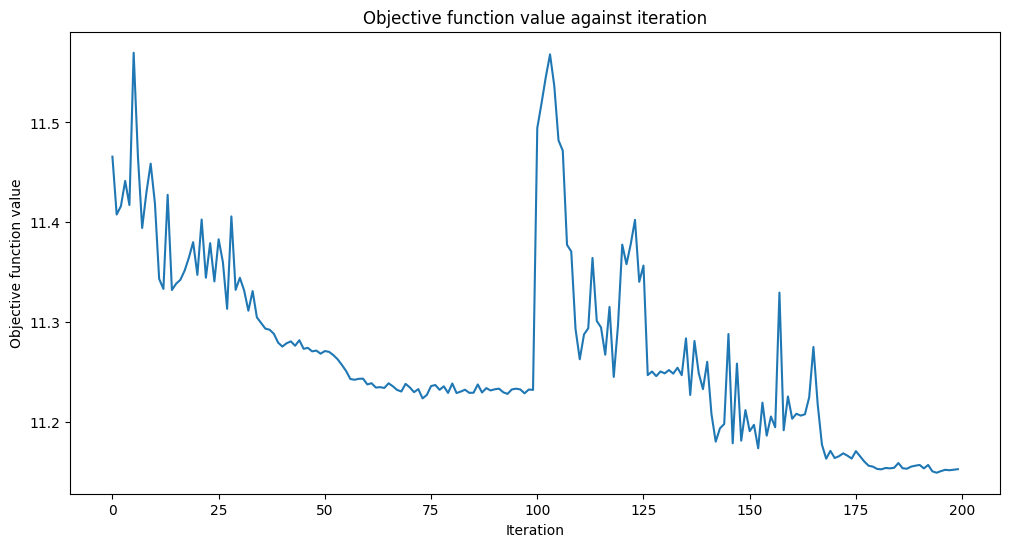

Training time: 137.59 seconds
Final objective function value: 11.1495
Number of optimization cycles: 100


In [99]:
start_time = time.time()
vqc2.fit(train_feature, train_labels)
end_time = time.time()

training_time = end_time - start_time
final_objective_value = vqc2._fit_result.fun
num_optimization_cycles = vqc2._fit_result.nfev

print(f"Training time: {training_time:.2f} seconds")
print(f"Final objective function value: {final_objective_value:.4f}")
print(f"Number of optimization cycles: {num_optimization_cycles}")

In [106]:
score_training = vqc2.score(train_feature, train_labels)
score_test = vqc2.score(test_feature, test_labels)

print(score_training)
print(score_test)

0.65
0.5666666666666667
